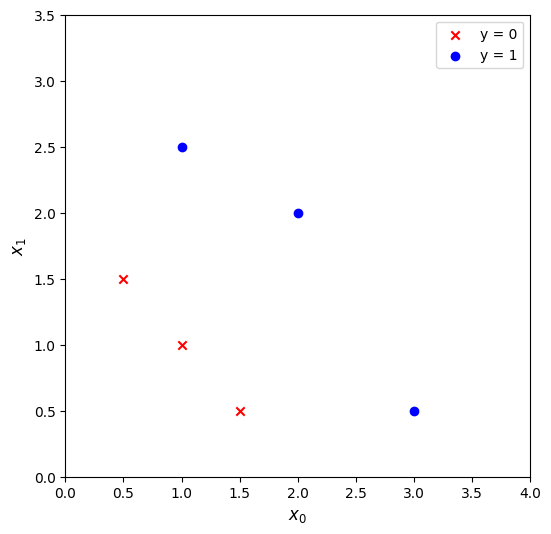

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import copy

X = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y = np.array([0, 0, 0, 1, 1, 1])

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
positive = y.flatten() == 1
negative = y.flatten() == 0
ax.scatter(X[negative, 0], X[negative, 1],marker='x', color='red', label='y = 0')
ax.scatter(X[positive, 0], X[positive, 1],marker='o', color='blue', label='y = 1')
ax.axis([0, 4, 0, 3.5])
ax.set_ylabel('$x_1$', fontsize=12)
ax.set_xlabel('$x_0$', fontsize=12)
ax.legend()
plt.show()

In [5]:
def sigmoid(z):
  g=1/(1+np.exp(-z))
  return g

def compute_cost_logistic(x,y,w,b):
  m,n=x.shape
  cost=0
  for i in range(m):
    z_i=np.dot(x[i],w)+b
    f_wb_i=sigmoid(z_i)
    cost+=-y[i]*np.log(f_wb_i)-(1-y[i])*np.log(1-f_wb_i)
  cost/=m
  return cost

def compute_gradient_logistic(x, y, w, b):
  m,n=x.shape
  dj_dw=np.zeros((n,))
  dj_db=0
  for i in range(m):
    f_wb_i=sigmoid(np.dot(x[i],w)+b)
    err_i=f_wb_i-y[i]
    for j in range(n):
      dj_dw[j]=dj_dw[j]+err_i*x[i,j]
    dj_db=dj_db+err_i
  dj_dw/=m
  dj_db/=m
  return dj_dw,dj_db

def gradient_descent(x,y,w_in,b_in,alpha,num_iters):
  j_his=[]
  b=b_in
  w=copy.deepcopy(w_in)
  for i in range(num_iters):
    dj_dw,dj_db=compute_gradient_logistic(x,y,w,b)
    w=w-alpha*dj_dw
    b=b-alpha*dj_db
    if i<100000:
      j_his.append(compute_cost_logistic(x,y,w,b))
  return w,b,j_his


In [8]:

w_in = np.zeros(X.shape[1])
b_in = 0.0
w_final, b_final, j_history = gradient_descent(X, y, w_in, b_in, alpha=0.1, num_iters=10000)
print("Final weights:", w_final)
print("Final bias:", b_final)
print("Final cost:", j_history[-1])


Final weights: [5.28123029 5.07815608]
Final bias: -14.222409982019837
Final cost: 0.017117768890292925


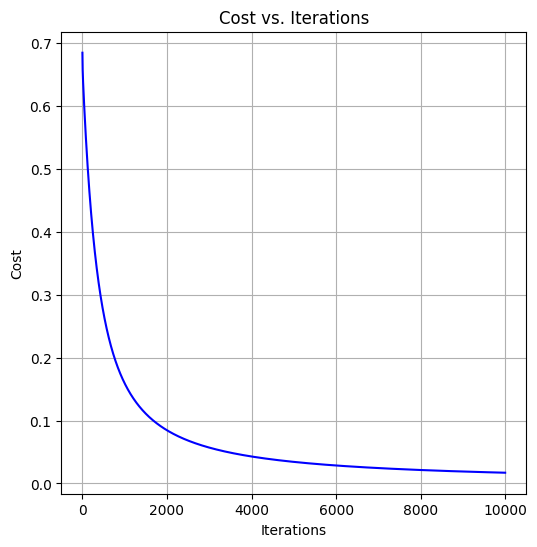

In [7]:

plt.figure(figsize=(6,6))
plt.plot(j_history,color="blue")
plt.title("Cost vs. Iterations")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.grid(True)
plt.show()


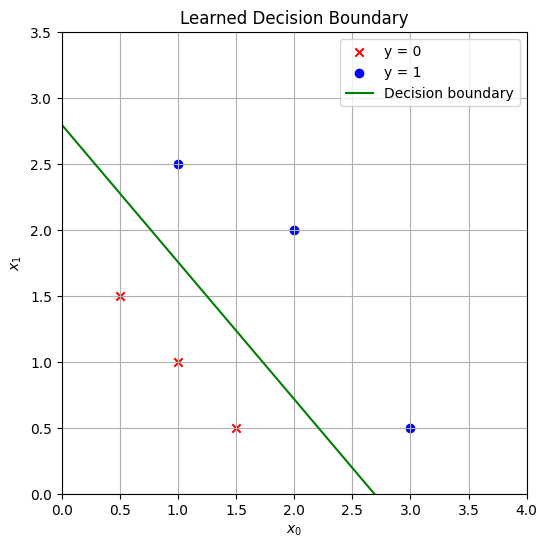

In [9]:
x0 = np.arange(0, 4, 0.1)
x1 = -(w_final[0] * x0 + b_final) / w_final[1]
fig, ax = plt.subplots(figsize=(6, 6))
positive = y == 1
negative = y == 0
ax.scatter(X[negative, 0], X[negative, 1],marker="x", color="red", label="y = 0")
ax.scatter(X[positive, 0], X[positive, 1],marker="o", color="blue", label="y = 1")
ax.plot(x0, x1, color="green", label="Decision boundary")
ax.set_xlim(0, 4)
ax.set_ylim(0, 3.5)
ax.set_xlabel("$x_0$")
ax.set_ylabel("$x_1$")
ax.set_title("Learned Decision Boundary")
ax.legend()
ax.grid(True)
plt.show()
